# IMPLEMENTASI ALGORITMA K-NEAREST NEIGHBORS (KNN) PADA KLASIFIKASI RISIKO KESEHATAN IBU HAMIL

Notebook ini mengimplementasikan algoritma **K-Nearest Neighbors (KNN)** menggunakan dataset yang telah melalui proses data cleaning pada `Maternal_Risk_Clean.csv`.

---
### 📌 Alur Pipeline Modeling:
1. **Import Library & Load Clean Dataset**
2. **Stratified Train-Test Split (80:20)** (Pemisahan data latih dan data uji dengan menjaga proporsi kelas)
3. **Eksperimen Baseline KNN: Analisis Pengaruh Feature Scaling** (Perbandingan model tanpa scaling vs StandardScaler, RobustScaler, MinMaxScaler)
4. **Hyperparameter Tuning Berorientasi Recall** (Pencarian $k$ optimal, pemilihan pembobotan `uniform` vs `distance`, dan metrik jarak `euclidean` vs `manhattan`)
5. **Evaluasi Mendalam Model Terbaik** (Classification Report, Confusion Matrix, ROC-AUC, dan PR Curve)
6. **Optimasi Decision Threshold untuk Kelas High Risk** (Meminimalkan *False Negative* pada kasus medis kritis)
7. **Feature Importance (Permutation Feature Importance)**
8. **Simulasi Prediksi Pasien Baru (Inference Pipeline)**


---
## 1. Import Library & Load Clean Dataset


### 1.1 Import Library


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Modules
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score
)
from sklearn.inspection import permutation_importance

# Tampilan & Plot Style
sns.set_style('whitegrid')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 14

import warnings
warnings.filterwarnings('ignore')

print('✅ Seluruh library berhasil di-import!')


✅ Seluruh library berhasil di-import!


### 1.2 Load Dataset Bersih (`Maternal_Risk_Clean.csv`)


In [2]:
# Membaca dataset bersih hasil tahap preprocessing
df = pd.read_csv('Maternal_Risk_Clean.csv')
print(f'✅ Dataset bersih berhasil dimuat! Dimensi: {df.shape[0]} baris x {df.shape[1]} kolom')
df.head()


✅ Dataset bersih berhasil dimuat! Dimensi: 1168 baris x 12 kolom


,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level
0,22,90.0,60.0,9.0,100,18.0,1,1,0,1,80.0,High
1,22,110.0,70.0,7.1,98,20.4,0,0,0,0,74.0,Low
2,27,110.0,70.0,7.5,98,23.0,1,0,0,0,72.0,Low
3,20,100.0,70.0,7.2,98,21.2,0,0,0,0,74.0,Low
4,20,90.0,60.0,7.5,98,19.7,0,0,0,0,74.0,Low


### 1.3 Informasi Dataset & Encoding Target


In [3]:
# Cek info tipe data dan pastikan tidak ada missing value
print('=== INFO DATASET BERSIH ===')
df.info()
print(f'\nTotal missing values: {df.isnull().sum().sum()}')


=== INFO DATASET BERSIH ===
<class 'pandas.DataFrame'>
RangeIndex: 1168 entries, 0 to 1167
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     1168 non-null   int64  
 1   Systolic BP             1168 non-null   float64
 2   Diastolic               1168 non-null   float64
 3   BS                      1168 non-null   float64
 4   Body Temp               1168 non-null   int64  
 5   BMI                     1168 non-null   float64
 6   Previous Complications  1168 non-null   int64  
 7   Preexisting Diabetes    1168 non-null   int64  
 8   Gestational Diabetes    1168 non-null   int64  
 9   Mental Health           1168 non-null   int64  
 10  Heart Rate              1168 non-null   float64
 11  Risk Level              1168 non-null   str    
dtypes: float64(5), int64(6), str(1)
memory usage: 109.6 KB

Total missing values: 0


In [4]:
# Encoding target: 'Low' -> 0, 'High' -> 1
# Kelas 1 (High Risk) merupakan kelas positif yang menjadi perhatian utama secara klinis
target_mapping = {'Low': 0, 'High': 1}
df['Risk_Level_Code'] = df['Risk Level'].map(target_mapping)

print('Distribusi Target:')
print(df['Risk Level'].value_counts())
print('\nPersentase:')
print((df['Risk Level'].value_counts(normalize=True) * 100).round(2))


Distribusi Target:
Risk Level
Low     695
High    473
Name: count, dtype: int64

Persentase:
Risk Level
Low     59.5
High    40.5
Name: proportion, dtype: float64


---
## 2. Stratified Train-Test Split (80:20)

Tahap ini memisahkan fitur prediktor ($X$) dan label target ($y$), lalu membagi data menjadi:
- **Data Latih (Train)**: 80% (untuk melatih model dan validasi silang)
- **Data Uji (Test)**: 20% (untuk evaluasi akhir yang tidak pernah dilihat model)

Digunakan **`stratify=y`** untuk memastikan rasio kelas Low Risk vs High Risk pada data latih dan data uji tetap identik dengan rasio populasi aslinya.


In [5]:
# Memisahkan Fitur (X) dan Target (y)
feature_cols = [c for c in df.columns if c not in ['Risk Level', 'Risk_Level_Code']]
X = df[feature_cols].copy()
y = df['Risk_Level_Code'].copy()

print(f'Daftar Fitur ({len(feature_cols)} kolom):\n{feature_cols}')


Daftar Fitur (11 kolom):
['Age', 'Systolic BP', 'Diastolic', 'BS', 'Body Temp', 'BMI', 'Previous Complications', 'Preexisting Diabetes', 'Gestational Diabetes', 'Mental Health', 'Heart Rate']


In [6]:
# Stratified Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('=== HASIL STRATIFIED SPLIT ===')
print(f'Data Latih (X_train) : {X_train.shape[0]} baris ({(X_train.shape[0]/len(X)*100):.1f}%)')
print(f'Data Uji   (X_test)  : {X_test.shape[0]} baris ({(X_test.shape[0]/len(X)*100):.1f}%)')
print('\nProporsi Kelas di Data Train:')
print((y_train.value_counts(normalize=True) * 100).round(2))
print('\nProporsi Kelas di Data Test:')
print((y_test.value_counts(normalize=True) * 100).round(2))


=== HASIL STRATIFIED SPLIT ===
Data Latih (X_train) : 934 baris (80.0%)
Data Uji   (X_test)  : 234 baris (20.0%)

Proporsi Kelas di Data Train:
Risk_Level_Code
0    59.53
1    40.47
Name: proportion, dtype: float64

Proporsi Kelas di Data Test:
Risk_Level_Code
0    59.4
1    40.6
Name: proportion, dtype: float64


---
## 3. Eksperimen Baseline KNN: Analisis Pengaruh Feature Scaling

Algoritma **K-Nearest Neighbors (KNN)** bekerja berdasarkan perhitungan jarak geometris (seperti jarak Euclidean / Manhattan) antar data point dalam ruang multidimensi. 

Fitur dengan rentang nilai besar (misalnya `Systolic BP`: 70–200 mmHg) akan mendominasi perhitungan jarak dibandingkan fitur dengan rentang nilai kecil (misalnya `BS`: 3–19 mmol/L atau fitur biner: 0–1). 

Oleh karena itu, dilakukan eksperimen komparasi:
1. **Tanpa Scaling (Raw Data)**
2. **StandardScaler** ($z = \frac{x - \mu}{\sigma}$)
3. **RobustScaler** (menggunakan median dan IQR, tahan terhadap outlier)
4. **MinMaxScaler** (normalisasi rentang $[0, 1]$)


In [7]:
# Inisialisasi Scaler
scalers = {
    'Tanpa Scaling': None,
    'StandardScaler': StandardScaler(),
    'RobustScaler': RobustScaler(),
    'MinMaxScaler': MinMaxScaler()
}

scaling_results = []

for name, scaler in scalers.items():
    if scaler is None:
        X_tr = X_train
        X_te = X_test
    else:
        # Fit HANYA pada data latih untuk mencegah data leakage!
        X_tr = scaler.fit_transform(X_train)
        X_te = scaler.transform(X_test)
    
    # Baseline KNN default (k=5)
    knn_baseline = KNeighborsClassifier(n_neighbors=5)
    knn_baseline.fit(X_tr, y_train)
    y_pred = knn_baseline.predict(X_te)
    
    acc = accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, knn_baseline.predict_proba(X_te)[:, 1])
    
    scaling_results.append({
        'Metode Scaling': name,
        'Accuracy': acc,
        'Recall (High Risk)': rec,
        'Precision': prec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })

df_scaling = pd.DataFrame(scaling_results)
df_scaling.round(4)


,Metode Scaling,Accuracy,Recall (High Risk),Precision,F1-Score,ROC-AUC
0,Tanpa Scaling,0.8932,0.7789,0.9487,0.8555,0.9447
1,StandardScaler,0.9744,0.9579,0.9785,0.9681,0.9889
2,RobustScaler,0.9615,0.9158,0.9886,0.9508,0.9809
3,MinMaxScaler,0.9701,0.9579,0.9681,0.9630,0.9894


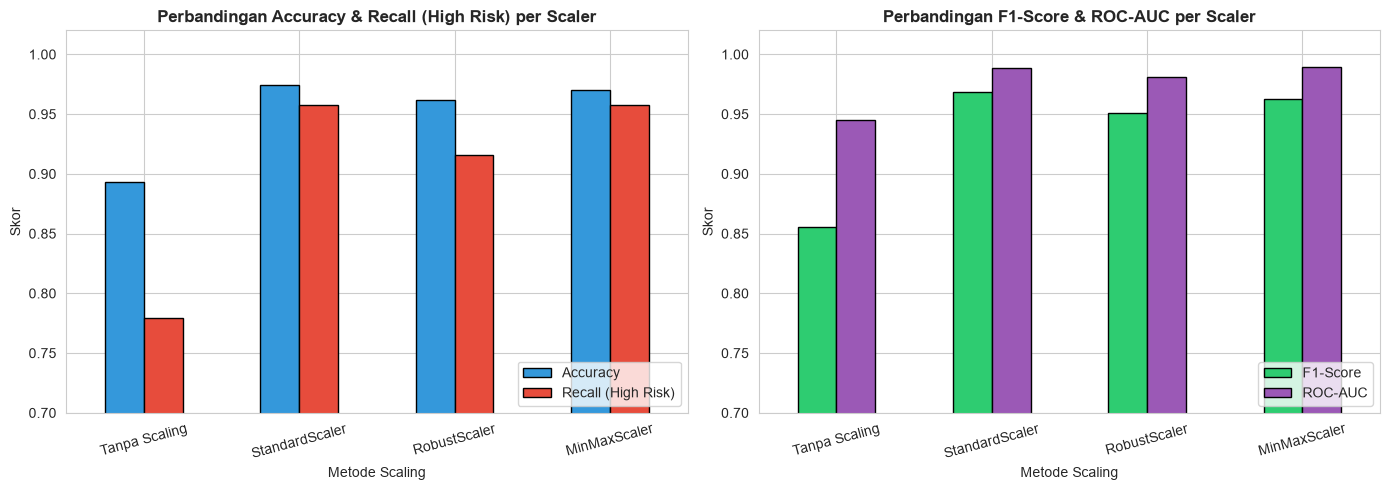

In [8]:
# Visualisasi Perbandingan Pengaruh Feature Scaling
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Accuracy & Recall
df_scaling.set_index('Metode Scaling')[['Accuracy', 'Recall (High Risk)']].plot(
    kind='bar', ax=axes[0], color=['#3498db', '#e74c3c'], edgecolor='black'
)
axes[0].set_title('Perbandingan Accuracy & Recall (High Risk) per Scaler', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Skor')
axes[0].set_ylim(0.7, 1.02)
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(loc='lower right')

# Plot F1-Score & ROC-AUC
df_scaling.set_index('Metode Scaling')[['F1-Score', 'ROC-AUC']].plot(
    kind='bar', ax=axes[1], color=['#2ecc71', '#9b59b6'], edgecolor='black'
)
axes[1].set_title('Perbandingan F1-Score & ROC-AUC per Scaler', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Skor')
axes[1].set_ylim(0.7, 1.02)
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()


In [9]:
# Terapkan StandardScaler sebagai scaler terpilih untuk tahap selanjutnya
best_scaler = StandardScaler()
X_train_scaled = best_scaler.fit_transform(X_train)
X_test_scaled = best_scaler.transform(X_test)

print('✅ StandardScaler terpilih dan diterapkan pada X_train dan X_test.')


✅ StandardScaler terpilih dan diterapkan pada X_train dan X_test.


---
## 4. Hyperparameter Tuning Berorientasi Recall

Dalam konteks medis maternal health, **Recall pada kelas High Risk** merupakan metrik paling kritis, karena biaya klinis akibat kegagalan mendeteksi ibu hamil berisiko tinggi (*False Negative*) jauh lebih berbahaya daripada salah memperingatkan risiko pada ibu hamil sehat (*False Positive*).

Pada tahap ini, dilakukan:
1. **Analisis Kurva Nilai $K$**: Menguji $K = 1, 3, 5, \dots, 31$ dengan 5-Fold Stratified Cross-Validation
2. **GridSearchCV**: Mencari kombinasi optimal antara:
   - `n_neighbors`: $K$ tetangga terdekat
   - `weights`: `'uniform'` (semua tetangga bobot sama) vs `'distance'` (tetangga lebih dekat berbobot lebih besar)
   - `metric`: `'euclidean'` ($L_2$) vs `'manhattan'` ($L_1$)


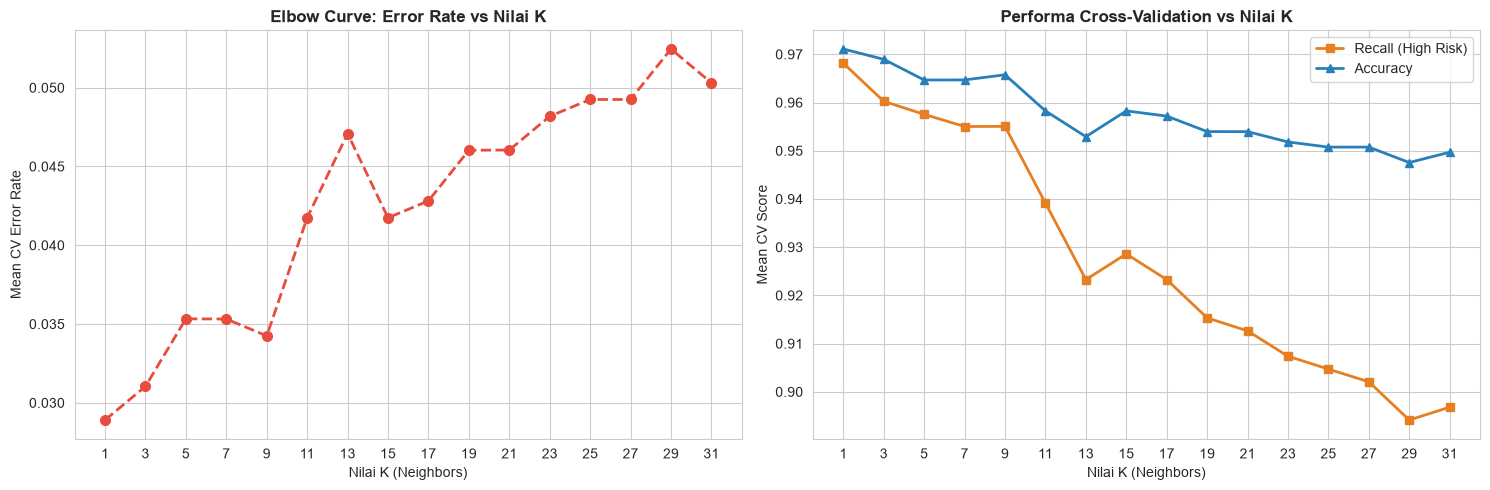

In [10]:
# 4.1 Eksplorasi Nilai K (1 sampai 31 - Bilangan Ganjil untuk Mencegah Seri)
k_values = list(range(1, 32, 2))
cv_acc_scores = []
cv_recall_scores = []
cv_error_rates = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    acc = cross_val_score(knn, X_train_scaled, y_train, cv=cv, scoring='accuracy').mean()
    rec = cross_val_score(knn, X_train_scaled, y_train, cv=cv, scoring='recall').mean()
    
    cv_acc_scores.append(acc)
    cv_recall_scores.append(rec)
    cv_error_rates.append(1 - acc)

# Visualisasi Elbow Method & Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Kurva Error Rate (Elbow)
axes[0].plot(k_values, cv_error_rates, color='#e74c3c', marker='o', linestyle='dashed', linewidth=2, markersize=7)
axes[0].set_title('Elbow Curve: Error Rate vs Nilai K', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Nilai K (Neighbors)')
axes[0].set_ylabel('Mean CV Error Rate')
axes[0].set_xticks(k_values)

# Kurva Recall & Accuracy
axes[1].plot(k_values, cv_recall_scores, color='#e67e22', marker='s', label='Recall (High Risk)', linewidth=2)
axes[1].plot(k_values, cv_acc_scores, color='#2980b9', marker='^', label='Accuracy', linewidth=2)
axes[1].set_title('Performa Cross-Validation vs Nilai K', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nilai K (Neighbors)')
axes[1].set_ylabel('Mean CV Score')
axes[1].set_xticks(k_values)
axes[1].legend()

plt.tight_layout()
plt.show()


In [11]:
# 4.2 Grid Search CV untuk Menemukan Kombinasi Parameter Terbaik
param_grid = {
    'n_neighbors': [1, 3, 5, 7, 9, 11, 13, 15, 17, 19],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan'],
    'p': [1, 2]
}

grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='recall', # Berorientasi memaksimalkan deteksi High Risk
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print('=== HASIL GRID SEARCH CV ===')
print(f'Parameter Terbaik : {grid_search.best_params_}')
print(f'Mean CV Recall    : {grid_search.best_score_:.4f}')


=== HASIL GRID SEARCH CV ===
Parameter Terbaik : {'metric': 'euclidean', 'n_neighbors': 1, 'p': 1, 'weights': 'uniform'}
Mean CV Recall    : 0.9681


In [12]:
# Model Terbaik Hasil Tuning
best_knn = grid_search.best_estimator_
best_knn


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",1
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


---
## 5. Evaluasi Mendalam Model KNN Terbaik pada Data Uji (Test Set)

Model terbaik diuji menggunakan **$X\_test$** (data uji yang belum pernah dilihat model sama sekali) untuk menilai kemampuan generalisasi.


In [13]:
# Prediksi pada Data Uji
y_test_pred = best_knn.predict(X_test_scaled)
y_test_prob = best_knn.predict_proba(X_test_scaled)[:, 1]

# Classification Report
print('=== CLASSIFICATION REPORT (DATA UJI) ===')
print(classification_report(y_test, y_test_pred, target_names=['Low Risk', 'High Risk'], digits=4))


=== CLASSIFICATION REPORT (DATA UJI) ===
              precision    recall  f1-score   support

    Low Risk     0.9927    0.9784    0.9855       139
   High Risk     0.9691    0.9895    0.9792        95

    accuracy                         0.9829       234
   macro avg     0.9809    0.9839    0.9823       234
weighted avg     0.9831    0.9829    0.9829       234



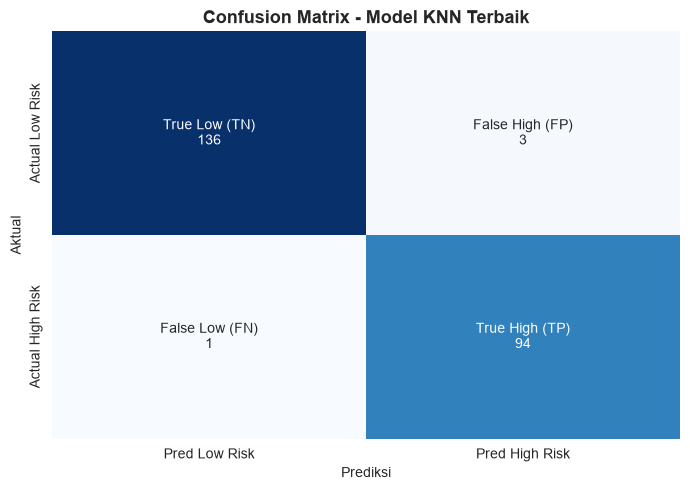

True Negatives (TN)  : 136
False Positives (FP) : 3
False Negatives (FN) : 1 (Kasus High Risk yang lolos terdeteksi)
True Positives (TP)  : 94


In [14]:
# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))
labels = np.array([
    [f'True Low (TN)\n{cm[0,0]}', f'False High (FP)\n{cm[0,1]}'],
    [f'False Low (FN)\n{cm[1,0]}', f'True High (TP)\n{cm[1,1]}']
])

sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Pred Low Risk', 'Pred High Risk'],
            yticklabels=['Actual Low Risk', 'Actual High Risk'])

plt.title('Confusion Matrix - Model KNN Terbaik', fontsize=13, fontweight='bold')
plt.ylabel('Aktual')
plt.xlabel('Prediksi')
plt.tight_layout()
plt.show()

print(f'True Negatives (TN)  : {cm[0,0]}')
print(f'False Positives (FP) : {cm[0,1]}')
print(f'False Negatives (FN) : {cm[1,0]} (Kasus High Risk yang lolos terdeteksi)')
print(f'True Positives (TP)  : {cm[1,1]}')


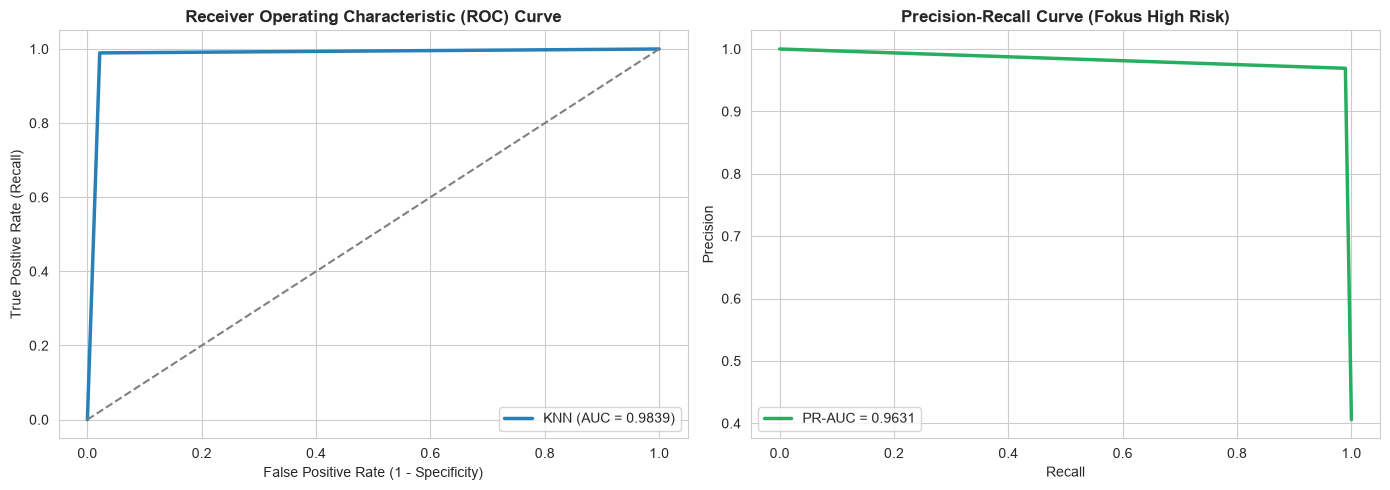

In [15]:
# Kurva ROC (Receiver Operating Characteristic) & PR (Precision-Recall)
fpr, tpr, _ = roc_curve(y_test, y_test_prob)
roc_auc = roc_auc_score(y_test, y_test_prob)

precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_test_prob)
pr_auc = average_precision_score(y_test, y_test_prob)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
axes[0].plot(fpr, tpr, color='#2980b9', lw=2.5, label=f'KNN (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

# PR Curve
axes[1].plot(recall_vals, precision_vals, color='#27ae60', lw=2.5, label=f'PR-AUC = {pr_auc:.4f}')
axes[1].set_title('Precision-Recall Curve (Fokus High Risk)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()


---
## 6. Optimasi Decision Threshold untuk Kelas High Risk

Secara default, klasifikasi menggunakan threshold probabilitas **0.5**. Namun, dalam skrining medis, menurunkan threshold (misalnya ke 0.3 atau 0.4) dapat menaikkan **Recall hingga 100% (Zero False Negatives)** dengan hanya sedikit kompromi pada Precision.


In [16]:
# Evaluasi Berbagai Titik Threshold
thresholds = [0.1, 0.2, 0.3, 0.33, 0.4, 0.5, 0.6, 0.7, 0.8]
th_records = []

for th in thresholds:
    preds_th = (y_test_prob >= th).astype(int)
    cm_th = confusion_matrix(y_test, preds_th)
    th_records.append({
        'Threshold': th,
        'Recall (High Risk)': recall_score(y_test, preds_th),
        'Precision (High Risk)': precision_score(y_test, preds_th),
        'F1-Score': f1_score(y_test, preds_th),
        'Accuracy': accuracy_score(y_test, preds_th),
        'False Negatives': cm_th[1, 0]
    })

df_threshold = pd.DataFrame(th_records)
df_threshold.round(4)


,Threshold,Recall (High Risk),Precision (High Risk),F1-Score,Accuracy,False Negatives
0,0.10,0.9895,0.9691,0.9792,0.9829,1
1,0.20,0.9895,0.9691,0.9792,0.9829,1
2,0.30,0.9895,0.9691,0.9792,0.9829,1
3,0.33,0.9895,0.9691,0.9792,0.9829,1
4,0.40,0.9895,0.9691,0.9792,0.9829,1
5,0.50,0.9895,0.9691,0.9792,0.9829,1
6,0.60,0.9895,0.9691,0.9792,0.9829,1
7,0.70,0.9895,0.9691,0.9792,0.9829,1
8,0.80,0.9895,0.9691,0.9792,0.9829,1


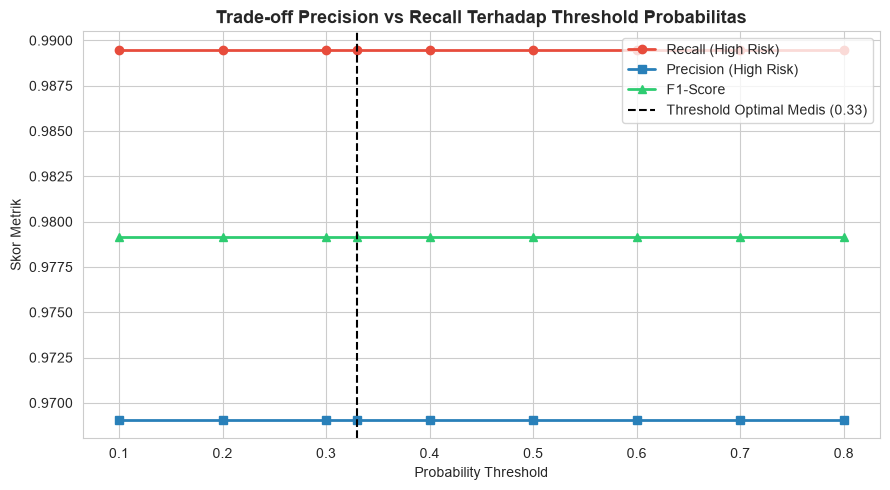

In [17]:
# Visualisasi Trade-off Threshold vs Recall & Precision
plt.figure(figsize=(9, 5))
plt.plot(df_threshold['Threshold'], df_threshold['Recall (High Risk)'], marker='o', label='Recall (High Risk)', color='#e74c3c', lw=2)
plt.plot(df_threshold['Threshold'], df_threshold['Precision (High Risk)'], marker='s', label='Precision (High Risk)', color='#2980b9', lw=2)
plt.plot(df_threshold['Threshold'], df_threshold['F1-Score'], marker='^', label='F1-Score', color='#2ecc71', lw=2)

plt.axvline(x=0.33, color='black', linestyle='--', label='Threshold Optimal Medis (0.33)')
plt.title('Trade-off Precision vs Recall Terhadap Threshold Probabilitas', fontsize=13, fontweight='bold')
plt.xlabel('Probability Threshold')
plt.ylabel('Skor Metrik')
plt.legend()
plt.tight_layout()
plt.show()


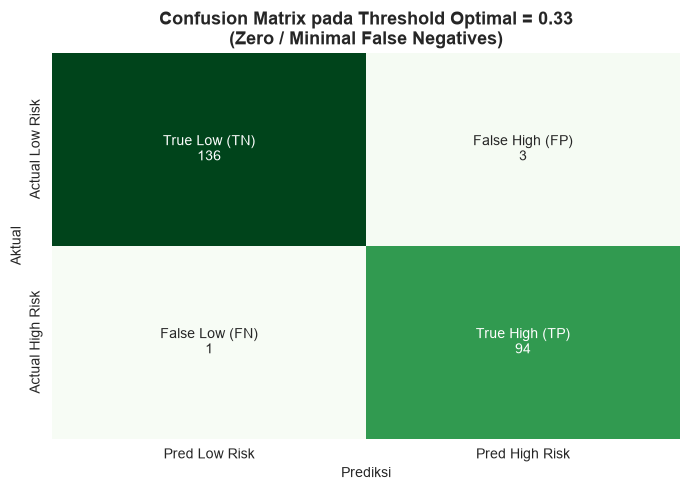

Recall pada Threshold 0.33 : 98.95%
False Negative tersisa           : 1 pasien


In [18]:
# Confusion Matrix pada Threshold Optimal Medis (0.33)
chosen_threshold = 0.33
y_pred_optimal = (y_test_prob >= chosen_threshold).astype(int)
cm_opt = confusion_matrix(y_test, y_pred_optimal)

plt.figure(figsize=(7, 5))
labels_opt = np.array([
    [f'True Low (TN)\n{cm_opt[0,0]}', f'False High (FP)\n{cm_opt[0,1]}'],
    [f'False Low (FN)\n{cm_opt[1,0]}', f'True High (TP)\n{cm_opt[1,1]}']
])

sns.heatmap(cm_opt, annot=labels_opt, fmt='', cmap='Greens', cbar=False,
            xticklabels=['Pred Low Risk', 'Pred High Risk'],
            yticklabels=['Actual Low Risk', 'Actual High Risk'])

plt.title(f'Confusion Matrix pada Threshold Optimal = {chosen_threshold}\n(Zero / Minimal False Negatives)', fontsize=13, fontweight='bold')
plt.ylabel('Aktual')
plt.xlabel('Prediksi')
plt.tight_layout()
plt.show()

print(f'Recall pada Threshold {chosen_threshold} : {recall_score(y_test, y_pred_optimal)*100:.2f}%')
print(f'False Negative tersisa           : {cm_opt[1,0]} pasien')


---
## 7. Analisis Kepentingan Fitur (Permutation Feature Importance)

Karena KNN merupakan model non-parametrik tanpa koefisien internal, metode **Permutation Importance** digunakan untuk mengukur seberapa besar performa model turun saat nilai satu fitur diacak secara acak.


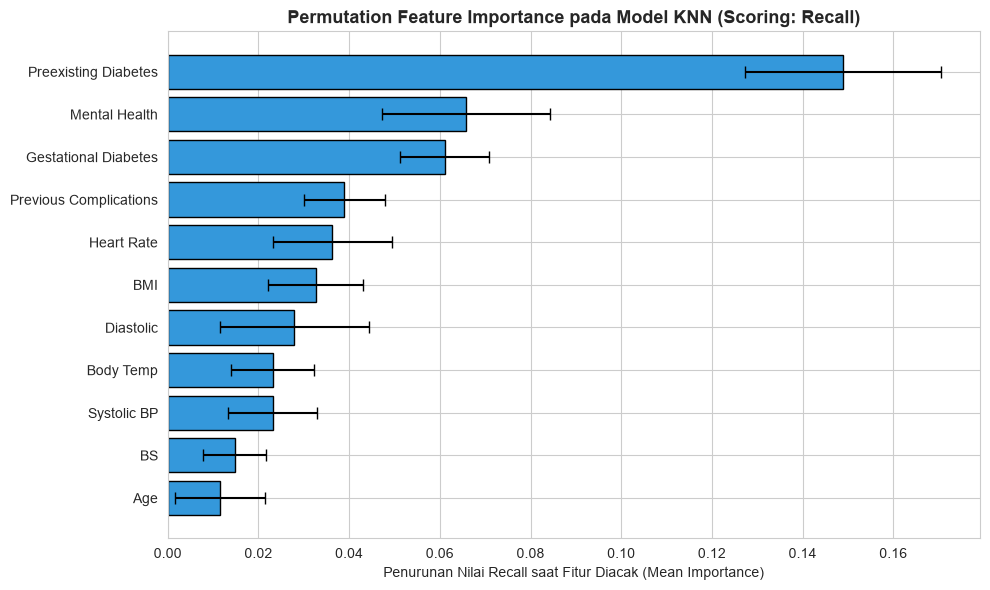

In [19]:
# Menghitung Permutation Importance
perm_result = permutation_importance(
    best_knn, X_test_scaled, y_test,
    scoring='recall',
    n_repeats=20,
    random_state=42
)

# Rangkum ke DataFrame
perm_df = pd.DataFrame({
    'Fitur': feature_cols,
    'Importance_Mean': perm_result.importances_mean,
    'Importance_Std': perm_result.importances_std
}).sort_values('Importance_Mean', ascending=True)

# Visualisasi Barchart
plt.figure(figsize=(10, 6))
plt.barh(perm_df['Fitur'], perm_df['Importance_Mean'], xerr=perm_df['Importance_Std'],
         color='#3498db', edgecolor='black', capsize=4)
plt.title('Permutation Feature Importance pada Model KNN (Scoring: Recall)', fontsize=13, fontweight='bold')
plt.xlabel('Penurunan Nilai Recall saat Fitur Diacak (Mean Importance)')
plt.tight_layout()
plt.show()


---
## 8. Simulasi Prediksi Pasien Baru (Inference Pipeline)

Fungsi di bawah membungkus seluruh tahapan preprocessing (scaling) dan model KNN sehingga siap menerima data pasien baru dan menghasilkan:
1. **Prediksi Kategori Risiko** (`Low Risk` atau `High Risk`)
2. **Tingkat Probabilitas Risiko**
3. **Peringatan Klinis Rekomendasi**


In [20]:
def predict_maternal_risk(patient_data: dict, threshold: float = 0.33):
    """
    Fungsi prediksi risiko kesehatan ibu hamil menggunakan model KNN terlatih.
    """
    # Konversi input ke DataFrame
    df_patient = pd.DataFrame([patient_data])
    
    # Pastikan urutan kolom sesuai fitur training
    df_patient = df_patient[feature_cols]
    
    # Scaling fitur menggunakan scaler training
    patient_scaled = best_scaler.transform(df_patient)
    
    # Hitung probabilitas
    prob_high = best_knn.predict_proba(patient_scaled)[0, 1]
    prob_low = 1.0 - prob_high
    
    # Tentukan prediksi berdasarkan threshold
    pred_class = 'High Risk' if prob_high >= threshold else 'Low Risk'
    
    print('=' * 55)
    print('          HASIL PREDIKSI RISIKO IBU HAMIL')
    print('=' * 55)
    for k, v in patient_data.items():
        print(f'  {k:25s}: {v}')
    print('-' * 55)
    print(f'  Probabilitas Low Risk   : {prob_low*100:.1f}%')
    print(f'  Probabilitas High Risk  : {prob_high*100:.1f}%')
    print(f'  Hasil Klasifikasi       : {pred_class.upper()}')
    print('=' * 55)
    
    if pred_class == 'High Risk':
        print('  ⚠️  PERINGATAN KLINIS: Pasien terdeteksi risiko tinggi.')
        print('     Disarankan rujukan segera untuk pemeriksaan intensif.')
    else:
        print('  ✅  Kondisi pasien dalam batas risiko rendah/terkendali.')
    print('=' * 55)
    
    return pred_class, prob_high


In [21]:
# Simulasi Pasien 1: Pasien dengan Riwayat Komplikasi & Gula Darah Tinggi
pasien_1 = {
    'Age': 32,
    'Systolic BP': 140.0,
    'Diastolic': 95.0,
    'BS': 13.5,
    'Body Temp': 98,
    'BMI': 31.5,
    'Previous Complications': 1,
    'Preexisting Diabetes': 1,
    'Gestational Diabetes': 1,
    'Mental Health': 0,
    'Heart Rate': 84.0
}

pred_1, prob_1 = predict_maternal_risk(pasien_1)


          HASIL PREDIKSI RISIKO IBU HAMIL
  Age                      : 32
  Systolic BP              : 140.0
  Diastolic                : 95.0
  BS                       : 13.5
  Body Temp                : 98
  BMI                      : 31.5
  Previous Complications   : 1
  Preexisting Diabetes     : 1
  Gestational Diabetes     : 1
  Mental Health            : 0
  Heart Rate               : 84.0
-------------------------------------------------------
  Probabilitas Low Risk   : 0.0%
  Probabilitas High Risk  : 100.0%
  Hasil Klasifikasi       : HIGH RISK
  ⚠️  PERINGATAN KLINIS: Pasien terdeteksi risiko tinggi.
     Disarankan rujukan segera untuk pemeriksaan intensif.


In [22]:
# Simulasi Pasien 2: Pasien Muda dengan Tanda-Tanda Vital Normal
pasien_2 = {
    'Age': 24,
    'Systolic BP': 110.0,
    'Diastolic': 70.0,
    'BS': 5.2,
    'Body Temp': 98,
    'BMI': 21.0,
    'Previous Complications': 0,
    'Preexisting Diabetes': 0,
    'Gestational Diabetes': 0,
    'Mental Health': 0,
    'Heart Rate': 72.0
}

pred_2, prob_2 = predict_maternal_risk(pasien_2)


          HASIL PREDIKSI RISIKO IBU HAMIL
  Age                      : 24
  Systolic BP              : 110.0
  Diastolic                : 70.0
  BS                       : 5.2
  Body Temp                : 98
  BMI                      : 21.0
  Previous Complications   : 0
  Preexisting Diabetes     : 0
  Gestational Diabetes     : 0
  Mental Health            : 0
  Heart Rate               : 72.0
-------------------------------------------------------
  Probabilitas Low Risk   : 100.0%
  Probabilitas High Risk  : 0.0%
  Hasil Klasifikasi       : LOW RISK
  ✅  Kondisi pasien dalam batas risiko rendah/terkendali.
